# FastSpeech 2 text-to-speech - English (Svarah)

This notebook trains a multi-speaker FastSpeech 2 text-to-speech model for English, using the PyTorch implementation
[ming024/FastSpeech2](https://github.com/ming024/FastSpeech2) with the modifications described in the project README.
It covers the full pipeline: data selection, pronunciation lexicon, forced alignment, feature extraction, training,
inference on the five test sentences, and the variance-adaptor plots (duration, pitch, energy).

**Data:** [Svarah](https://huggingface.co/datasets/ai4bharat/Svarah) (`ai4bharat/Svarah`), 9.6 h of Indian-accented English from 117 speakers (read and conversational speech).

**Runtime.** Data preparation (sections 2-11) runs on CPU; training (sections 13-15) needs a GPU. The notebook can be run
with *Runtime -> Run all*: stages that are already complete are skipped, and a stage that fails stops the run.
If the runtime has no GPU, execution stops before training with a message; switching the runtime type to a T4 GPU and
running all cells again continues from there. Prepared data and checkpoints are kept on Google Drive, so a disconnected
session can resume.

## 1. Environment
Checks for a GPU and defines two small helpers: `sh()` runs a shell command and raises on failure, `have()` tests whether files exist.

In [1]:
!nvidia-smi -L || echo 'No GPU in this session'

import os, glob, subprocess, shutil, zipfile

def sh(cmd):
    # run a shell command, stream its output, and raise if it fails
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, bufsize=1, executable='/bin/bash')
    out = []
    for line in p.stdout:
        print(line, end=''); out.append(line)
    if p.wait() != 0:
        raise RuntimeError('Command failed (exit code %d) - see the output above.' % p.returncode)
    return ''.join(out)

def have(pattern):
    return len(glob.glob(pattern)) > 0

os.environ['FS2_WORK'] = '/content/work'
print('helpers ready')

/bin/bash: line 1: nvidia-smi: command not found
No GPU in this session
helpers ready


## 2. Project code
Mounts Google Drive and unpacks `project.zip` (the code, configuration files and pretrained HiFi-GAN vocoder). Prepared data and checkpoints are stored in `fs2_english/` on Drive.

In [2]:
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content')
shutil.rmtree('/content/project', ignore_errors=True)
zipfile.ZipFile('/content/drive/MyDrive/project.zip').extractall('/content')
os.chdir('/content/project')
os.makedirs('/content/drive/MyDrive/fs2_english', exist_ok=True)
PREP_TAR = '/content/drive/MyDrive/fs2_english/prepared_data.tar'
print('code ready:', os.listdir('/content/project'))

Mounted at /content/drive
code ready: ['fastspeech2', 'requirements.txt', 'common', 'Results', 'Report', 'README.md', 'notebooks', 'tests', '.gitignore', 'English', 'Telugu']


## 3. Python dependencies
Installs the audio, alignment-file and text-processing packages; PyTorch is already part of the Colab image. NLTK data is needed by the grapheme-to-phoneme tool.

In [3]:
sh('pip install -q pyworld tgt g2p-en inflect soundfile librosa pyyaml scikit-learn matplotlib datasets unidecode')
import nltk
for p in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng', 'cmudict']:
    nltk.download(p, quiet=True)
print('ok')

ok


## 4. Montreal Forced Aligner
FastSpeech 2 needs the duration of every phone, which comes from forced alignment of each recording against its transcript.
The Montreal Forced Aligner (MFA) is installed with micromamba in its own environment so it does not interfere with the
Python packages above. The step is skipped when prepared data already exists on Drive.

In [4]:
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - aligner not needed')
else:
    sh('''
    set -e
    export MAMBA_ROOT_PREFIX=$HOME/micromamba
    if [ ! -f $MAMBA_ROOT_PREFIX/bin/micromamba ]; then
      mkdir -p $MAMBA_ROOT_PREFIX/bin
      curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C $MAMBA_ROOT_PREFIX bin/micromamba
    fi
    if [ ! -d $MAMBA_ROOT_PREFIX/envs/mfa ]; then
      $MAMBA_ROOT_PREFIX/bin/micromamba create -y -n mfa -c conda-forge python=3.11 montreal-forced-aligner
    fi
    $MAMBA_ROOT_PREFIX/bin/micromamba run -n mfa mfa version
    ''')

prepared data found on Drive - aligner not needed


## 5. Hugging Face access
1. Create a Hugging Face account (or log in).
2. Open https://huggingface.co/datasets/ai4bharat/Svarah and accept the dataset conditions (*Agree and access repository*) - the dataset is gated.
3. Create a read token at https://huggingface.co/settings/tokens (*Create new token* -> type **Read**) and paste it in the prompt below.

The token is read through a hidden prompt and is not stored in the notebook.

In [5]:
from getpass import getpass
if os.path.exists(PREP_TAR):
    print('prepared data found on Drive - token not needed')
elif not os.environ.get('HF_TOKEN'):
    os.environ['HF_TOKEN'] = getpass('Hugging Face token: ')
    print('token received, length', len(os.environ['HF_TOKEN']))

prepared data found on Drive - token not needed


## 6. Restore previously prepared data
If a previous session already finished sections 7-10, the prepared data is restored from Drive and those stages are skipped.

In [4]:
tar = PREP_TAR
if not have('/content/work/preprocessed_data/*/train.txt') and os.path.exists(tar):
    os.makedirs('/content/work', exist_ok=True)
    sh('tar -xf ' + tar + ' -C /content')
    print('restored prepared data from Drive')
else:
    print('nothing to restore')

restored prepared data from Drive


## 7. Data selection
Svarah has no speaker-ID column, so speakers are approximated by the unique combinations of the speaker metadata columns (gender, age group, native language and place, qualification, occupation); every pseudo-speaker contributes the same fraction of its audio.
Clips shorter than 1 s or longer than the limit set in `config.yaml` are dropped, and the selected clips are split by
utterance into training (~5 h) and validation (~1 h) sets, so no clip appears in both. Audio is resampled to 22.05 kHz mono and
the transcripts are normalised. The per-speaker statistics are written to `selection_stats.json`.

In [ ]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
elif have('/content/work/raw_data/*/split.json'):
    print('data already downloaded - skipping')
else:
    sh('python English/preprocess.py --stage select')


===== stage: select =====
loading ai4bharat/Svarah ...

Generating test split: 100%|██████████| 6656/6656 [00:17<00:00, 376.36 examples/s]
splits: {'test': 6656}
columns: ['audio_filepath', 'duration', 'text', 'gender', 'age-group', 'primary_language', 'native_place_state', 'native_place_district', 'highest_qualification', 'job_category', 'occupation_domain']
columns -> audio: 'audio_filepath', text: 'text', speaker: 'gender'
no speaker-id column: pseudo-speakers = unique combinations of ['gender', 'age-group', 'primary_language', 'native_place_state', 'native_place_district', 'highest_qualification', 'job_category', 'occupation_domain']
usable clips: 4955 (7.13 h); dropped: {'too short': 1215, 'too long': 486}
speakers: 115 total, 103 kept (>= 60 s usable audio)
available 6.97 h, wanted 6.00 h -> every speaker contributes 86.0% of its audio
exported: train 4.99 h (3452 clips), val 1.11 h (748 clips), 103 speakers

preprocessing stage(s) finished OK


In [ ]:
sh('cat /content/work/raw_data/*/selection_stats.json | head -40')

{
  "train_hours": 4.98638138888889,
  "val_hours": 1.1090703819444445,
  "train_utterances": 3452,
  "val_utterances": 748,
  "n_speakers": 103,
  "dropped": {
    "too short": 1215,
    "too long": 486
  },
  "pseudo_speaker_columns": [
    "gender",
    "age-group",
    "primary_language",
    "native_place_state",
    "native_place_district",
    "highest_qualification",
    "job_category",
    "occupation_domain"
  ],
  "pseudo_speaker_keys": {
    "spk000": [
      "Female",
      "18-30",
      "Kannada",
      "Karnataka",
      "Hassan",
      "Post Graduate",
      "Full Time",
      "Technology and Services"
    ],
    "spk001": [
      "Female",
      "30-45",
      "Kannada",
      "Karnataka",
      "Gulbarga",
      "Post Graduate",
      "Full Time",
      "Technology and Services"


'{\n  "train_hours": 4.98638138888889,\n  "val_hours": 1.1090703819444445,\n  "train_utterances": 3452,\n  "val_utterances": 748,\n  "n_speakers": 103,\n  "dropped": {\n    "too short": 1215,\n    "too long": 486\n  },\n  "pseudo_speaker_columns": [\n    "gender",\n    "age-group",\n    "primary_language",\n    "native_place_state",\n    "native_place_district",\n    "highest_qualification",\n    "job_category",\n    "occupation_domain"\n  ],\n  "pseudo_speaker_keys": {\n    "spk000": [\n      "Female",\n      "18-30",\n      "Kannada",\n      "Karnataka",\n      "Hassan",\n      "Post Graduate",\n      "Full Time",\n      "Technology and Services"\n    ],\n    "spk001": [\n      "Female",\n      "30-45",\n      "Kannada",\n      "Karnataka",\n      "Gulbarga",\n      "Post Graduate",\n      "Full Time",\n      "Technology and Services"\n'

## 8. Pronunciation lexicon and forced alignment
The lexicon maps every word of the selected transcripts to phones. The aligner is then trained on the selected data with a
monophone + triphone recipe (MFA's additional LDA-MLLT and speaker-adaptive stages are skipped to keep the runtime
manageable) and writes one phone-level TextGrid per utterance. Utterances the aligner cannot align are reported and excluded.

In [ ]:
if have('/content/work/preprocessed_data/*/train.txt'):
    print('data already prepared - skipping')
else:
    sh('python English/preprocess.py --stage lexicon')
    if have('/content/work/preprocessed_data/*/TextGrid/*/*.TextGrid'):
        print('alignment already done - skipping')
    else:
        sh('python English/preprocess.py --stage align --num_jobs 4')


===== stage: lexicon =====
lexicon: 6533 words -> /content/work/lexicon.txt

preprocessing stage(s) finished OK

===== stage: align =====
running: /root/micromamba/bin/micromamba run -r /root/micromamba -n mfa mfa train --clean -j 4 --output_directory /content/work/preprocessed_data/Svarah/TextGrid /content/work/raw_data/Svarah /content/work/lexicon.txt /content/work/mfa_acoustic_model.zip
 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4,200/100  [ 0:00:00 < 0:00:00 , 952 it/s ]
 INFO     Found 103 speakers across 4200 files, average number of utterances per
          speaker: 40.77669902912621                                            
 INFO     Initializing multiprocessing jobs...                                  
 INFO     Normalizing text...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4,

## 9. Feature extraction
Computes mel-spectrograms, phoneme-level pitch (F0) and energy, and durations from the alignments. Pitch and energy statistics for normalisation are fitted on the training files only.

In [7]:
if not have('/content/work/preprocessed_data/*/train.txt'):
    sh('python English/preprocess.py --stage features')
sh('cat /content/work/preprocessed_data/*/preprocess_summary.json')

{
  "train": {
    "utterances": 3437,
    "hours": 3.689,
    "speakers": 103
  },
  "val": {
    "utterances": 744,
    "hours": 0.816,
    "speakers": 103
  }
}

'{\n  "train": {\n    "utterances": 3437,\n    "hours": 3.689,\n    "speakers": 103\n  },\n  "val": {\n    "utterances": 744,\n    "hours": 0.816,\n    "speakers": 103\n  }\n}'

## 10. Back up the prepared data
Archives the prepared data to Drive so that a later session can skip sections 7-9.

In [8]:
import tarfile
files = ['work/preprocessed_data', 'work/lexicon.txt']
for pat in ('split.json', 'selection_stats.json'):
    files += [os.path.relpath(p, '/content') for p in glob.glob('/content/work/raw_data/*/' + pat)]
tmp = '/content/drive/MyDrive/fs2_english/prepared_data.tar.part'
with tarfile.open(tmp, 'w') as t:
    for f in files:
        t.add('/content/' + f, arcname=f)
os.replace(tmp, '/content/drive/MyDrive/fs2_english/prepared_data.tar')
sh('ls -lh /content/drive/MyDrive/fs2_english/')

total 498M
drwx------ 2 root root 4.0K Nov  4 12:30 ckpt
drwx------ 2 root root 4.0K Nov  4 12:30 log
-rw------- 1 root root 498M Nov  4 13:10 prepared_data.tar


'total 498M\ndrwx------ 2 root root 4.0K Nov  4 12:30 ckpt\ndrwx------ 2 root root 4.0K Nov  4 12:30 log\n-rw------- 1 root root 498M Nov  4 13:10 prepared_data.tar\n'

## 11. Sanity check
Plays a few of the selected recordings with their transcripts.

In [15]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/work/raw_data/*/*/*.wav'))[::700][:4]:
    print(w); print(open(w[:-4] + '.lab', encoding='utf-8').read()); ipd.display(ipd.Audio(w))

## 12. GPU check
Training requires a GPU. If the session has none, execution stops here; the prepared data is already saved.

In [10]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Data preparation is complete and saved to Drive. No GPU in this session, so stopping before training. '
                       'Switch the runtime type to a T4 GPU (Runtime > Change runtime type) and run all cells again; completed stages are skipped.')
print('GPU available:', torch.cuda.get_device_name(0))

GPU available: Tesla T4


## 13. Smoke test
Runs 30 training steps and one validation pass to confirm that the data, model and loss are wired up correctly. Skipped when a training run already exists.

In [ ]:
import re
p1 = '/content/project/fastspeech2/utils/tools.py'
s = open(p1).read()
s = re.sub(r"energies = torch\.from_numpy\(energies\)(\.float\(\))?\.to\(device\)",
           "energies = torch.from_numpy(energies).float().to(device)", s)
open(p1, 'w').write(s)
p2 = '/content/project/fastspeech2/model/loss.py'
t = open(p2).read()
if 'FP32-FIX' not in t:
    t = t.replace("        src_masks = ~src_masks\n",
                  "        pitch_targets = pitch_targets.float(); energy_targets = energy_targets.float(); mel_targets = mel_targets.float()  # FP32-FIX\n        src_masks = ~src_masks\n", 1)
    open(p2, 'w').write(t)
print('tools.py fixed:', 'energies).float()' in open(p1).read())
print('loss.py fixed :', 'FP32-FIX' in open(p2).read())
if os.path.exists('/content/drive/MyDrive/fs2_english/ckpt/resume.pth.tar'):
    print('training already started earlier - skipping the smoke test')
else:
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)
    sh('python English/train.py --total_step 30 --plots_dir /tmp/testplots')
    shutil.rmtree('/content/work/ckpt', ignore_errors=True); shutil.rmtree('/content/work/log', ignore_errors=True)

tools.py fixed: True
loss.py fixed : True
parameters: 35.1 M, device: cuda
starting from scratch
VALIDATION step 30  total 9.971 (mel 3.829 postnet 2.191 pitch 0.954 energy 1.179 dur 1.817)
  new best validation loss -> best_model_fp16.pth
saved checkpoint at step 30 (final)
finished at step 30
no /content/work/log/train_loss.csv
wrote /tmp/testplots/validation_loss.png


## 14. Training
30,000 steps, batch size 16 (see `config.yaml`). Losses are logged to CSV every 50 steps and the validation loss is computed on the full
validation set every 500 steps. Checkpoints go to Drive and the run resumes automatically; the cell stops after 170 minutes
to stay within the Colab session limit and can simply be run again to continue. The best model (lowest validation loss) is kept separately.

In [12]:
import re
for d in ('ckpt', 'log'):
    target = '/content/drive/MyDrive/fs2_english/' + d
    os.makedirs(target, exist_ok=True)
    link = '/content/work/' + d
    if not os.path.islink(link):
        if os.path.exists(link):
            shutil.rmtree(link)
        os.symlink(target, link)
out = sh('python English/train.py --max_minutes 170')
m = re.findall(r'finished at step (\d+)', out)
TOTAL = 30000
if not m or int(m[-1]) < TOTAL:
    raise RuntimeError('Training paused at step %s of %d (session time limit). Re-run this cell to resume.' % (m[-1] if m else '?', TOTAL))
print('training finished')

parameters: 35.1 M, device: cuda
RESUMED from step 25975 (best val so far 3.3381)
step 26000/30000  loss 1.765 (mel 0.499 postnet 0.499 pitch 0.257 energy 0.367 dur 0.143)
VALIDATION step 26000  total 3.595 (mel 1.007 postnet 1.007 pitch 0.552 energy 0.855 dur 0.175)
saved checkpoint at step 26000 
step 26050/30000  loss 1.731 (mel 0.498 postnet 0.498 pitch 0.234 energy 0.355 dur 0.147)
step 26100/30000  loss 1.711 (mel 0.497 postnet 0.496 pitch 0.220 energy 0.353 dur 0.146)
step 26150/30000  loss 1.738 (mel 0.497 postnet 0.497 pitch 0.234 energy 0.362 dur 0.147)
step 26200/30000  loss 1.718 (mel 0.497 postnet 0.496 pitch 0.217 energy 0.362 dur 0.146)
step 26250/30000  loss 1.719 (mel 0.495 postnet 0.495 pitch 0.226 energy 0.358 dur 0.145)
step 26300/30000  loss 1.721 (mel 0.498 postnet 0.497 pitch 0.230 energy 0.351 dur 0.145)
step 26350/30000  loss 1.724 (mel 0.496 postnet 0.495 pitch 0.229 energy 0.360 dur 0.144)
step 26400/30000  loss 1.733 (mel 0.499 postnet 0.498 pitch 0.231 ener

## 15. Inference and plots
Synthesises the five test sentences with the best checkpoint and saves the audio, the predicted duration / pitch (F0) / energy
per phone for each sentence, the mel-spectrograms, and the training and validation loss curves to `Results/English/`.

In [13]:
sh('python English/inference.py --checkpoint best --all_speakers')
sh('python English/train.py --plots_only --plots_dir /content/project/Results/English')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/best_model_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 87 phones, 5.86 s
E2a: 51 phones, 3.46 s
E2b: 56 phones, 3.82 s
E3: 37 phones, 2.45 s
E4: 81 phones, 5.50 s
done. audio -> /content/project/Results/English/test_generated_audios | plots -> /content/project/Results/English/variance_adaptor_plots
wrote /content/project/Results/English/training_loss.png
wrote /content/project/Results/English/validation_loss.png


'wrote /content/project/Results/English/training_loss.png\nwrote /content/project/Results/English/validation_loss.png\n'

In [14]:
import IPython.display as ipd
for w in sorted(glob.glob('/content/project/Results/English/test_generated_audios/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

E1.wav


E2a.wav


E2b.wav


E3.wav


E4.wav


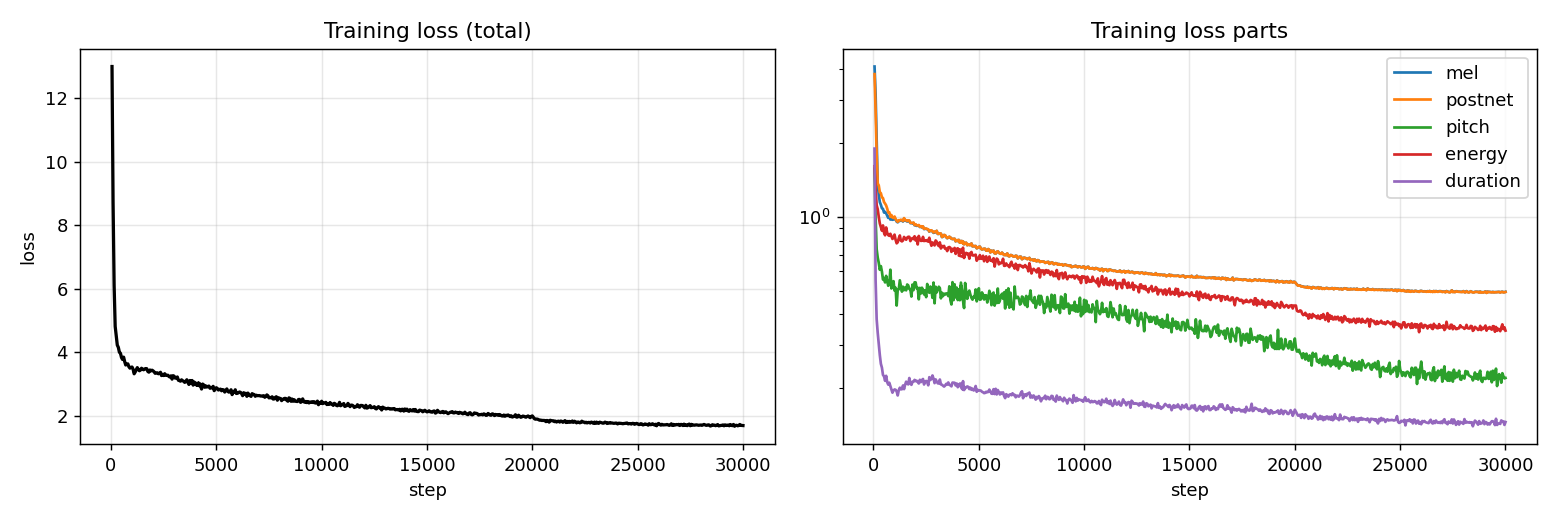

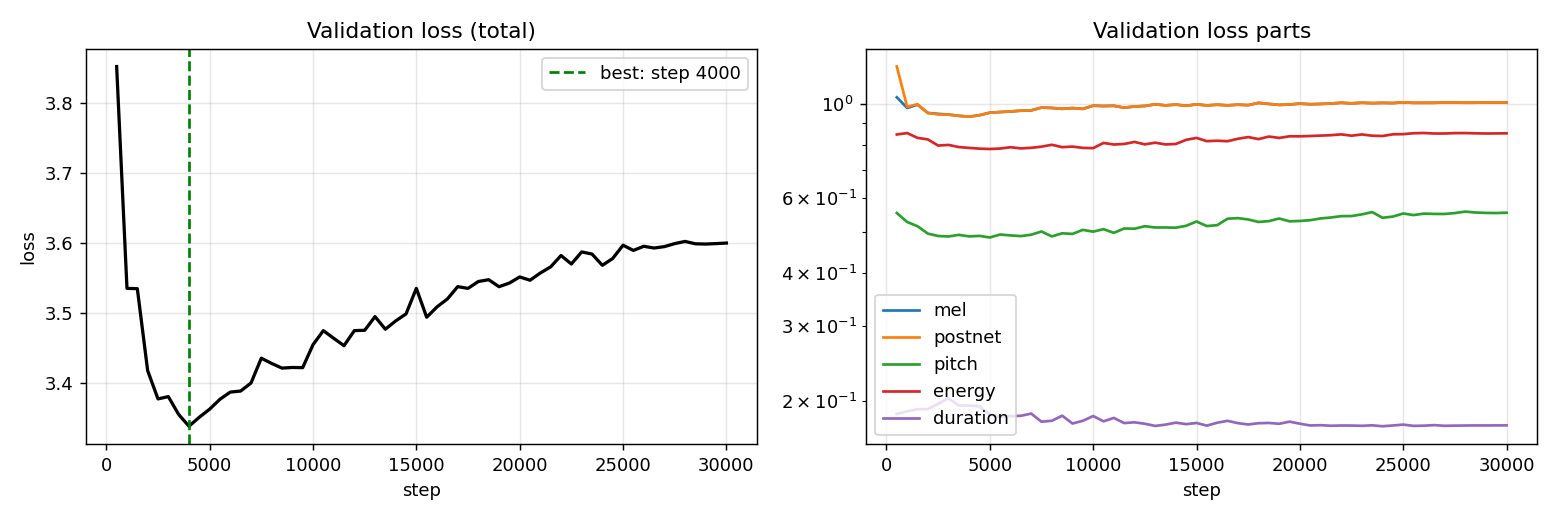

In [15]:
from IPython.display import Image, display
for p in ['training_loss.png', 'validation_loss.png']:
    display(Image('/content/project/Results/English/' + p))

## 16. Additional experiments
Two ablations on the English front end:
1. **Context-aware vs. dictionary pronunciation.** `g2p_en` run on the whole sentence can assign different stress to heteronyms
   (noun vs. verb *conduct*, E2a / E2b); plain word-by-word lexicon lookup cannot.
2. **Number / time normalisation off** for E4 (*10:45 AM, 12 November 2026*). `g2p_en` expands digits on its own, so the difference may be small.

In [16]:
sh('python English/inference.py --checkpoint best --g2p_mode lexicon --out_dir /content/project/Results/English/extra/plain_dictionary')
sh('python English/inference.py --checkpoint best --no_normalize --out_dir /content/project/Results/English/extra/no_normalisation')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/best_model_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 85 phones, 5.74 s
E2a: 50 phones, 3.34 s
E2b: 56 phones, 3.81 s
E3: 37 phones, 2.43 s
E4: 79 phones, 5.45 s
done. audio -> /content/project/Results/English/extra/plain_dictionary/test_generated_audios | plots -> /content/project/Results/English/extra/plain_dictionary/variance_adaptor_plots
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/best_model_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers 

'/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.\n  WeightNorm.apply(module, name, dim)\ncheckpoint: /content/work/ckpt/best_model_fp16.pth\nRemoving weight norm...\nmain speaker: spk013 (id 13); 103 speakers in model\nE1: 87 phones, 5.86 s\nE2a: 51 phones, 3.46 s\nE2b: 56 phones, 3.82 s\nE3: 37 phones, 2.45 s\nE4: 79 phones, 5.33 s\ndone. audio -> /content/project/Results/English/extra/no_normalisation/test_generated_audios | plots -> /content/project/Results/English/extra/no_normalisation/variance_adaptor_plots\n'

## 17. Export
Copies the checkpoints (fp16 weights, ~70 MB each), the dataset statistics and the loss logs next to the results, and writes two archives to Drive.

In [13]:
os.makedirs('/content/project/English/checkpoints', exist_ok=True)
for f in ('best_model_fp16.pth', 'last_model_fp16.pth'):
    shutil.copy('/content/drive/MyDrive/fs2_english/ckpt/' + f, '/content/project/English/checkpoints/' + f)
for f in glob.glob('/content/work/preprocessed_data/*/preprocess_summary.json') + glob.glob('/content/work/raw_data/*/selection_stats.json'):
    shutil.copy(f, '/content/project/Results/English/')
shutil.copy('/content/work/log/train_loss.csv', '/content/project/Results/English/')
shutil.copy('/content/work/log/val_loss.csv', '/content/project/Results/English/')
shutil.make_archive('/content/drive/MyDrive/English_results', 'zip', '/content/project', 'Results/English')
shutil.make_archive('/content/drive/MyDrive/English_checkpoints', 'zip', '/content/project', 'English/checkpoints')
print('saved: English_results.zip and English_checkpoints.zip (in My Drive)')

saved: English_results.zip and English_checkpoints.zip (in My Drive)


In [18]:
print('energies).float()' in open('/content/project/fastspeech2/utils/tools.py').read())

True


In [19]:
sh('python English/inference.py --checkpoint last --all_speakers --out_dir /content/project/Results/English_last')
import IPython.display as ipd
for w in sorted(glob.glob('/content/project/Results/English_last/test_generated_audios/*.wav')):
    print(w.split('/')[-1]); ipd.display(ipd.Audio(w))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/last_model_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 87 phones, 5.63 s
E2a: 51 phones, 3.72 s
E2b: 56 phones, 3.80 s
E3: 37 phones, 2.61 s
E4: 81 phones, 5.63 s
done. audio -> /content/project/Results/English_last/test_generated_audios | plots -> /content/project/Results/English_last/variance_adaptor_plots
E1.wav


E2a.wav


E2b.wav


E3.wav


E4.wav


In [20]:
R = '/content/project/Results/English'
C = R + '/extra/checkpoint_comparison'
os.makedirs(C, exist_ok=True)
for d in ('test_generated_audios', 'variance_adaptor_plots'):
    if not os.path.exists(C + '/best_step4000/' + d):
        shutil.copytree(R + '/' + d, C + '/best_step4000/' + d)
    if not os.path.exists(C + '/last_step30000/' + d):
        shutil.copytree('/content/project/Results/English_last/' + d, C + '/last_step30000/' + d)
sh('python English/inference.py --checkpoint last --g2p_mode lexicon --out_dir ' + C + '/last_step30000/extra_plain_dictionary')
sh('python English/inference.py --checkpoint last --no_normalize --out_dir ' + C + '/last_step30000/extra_no_normalisation')
print(sorted(os.listdir(C)))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/last_model_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 85 phones, 5.46 s
E2a: 50 phones, 3.65 s
E2b: 56 phones, 3.77 s
E3: 37 phones, 2.61 s
E4: 79 phones, 5.40 s
done. audio -> /content/project/Results/English/extra/checkpoint_comparison/last_step30000/extra_plain_dictionary/test_generated_audios | plots -> /content/project/Results/English/extra/checkpoint_comparison/last_step30000/extra_plain_dictionary/variance_adaptor_plots
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/l

In [21]:
import json, re, torch, soundfile as sf
from transformers import pipeline
asr = pipeline('automatic-speech-recognition', model='openai/whisper-small',
               device=0 if torch.cuda.is_available() else -1)
ref = {s['id']: s['text'] for s in json.load(open('/content/project/English/test_sentences.json'))['sentences']}
def words(t): return re.sub(r"[^a-z0-9' ]", ' ', t.lower()).split()
def wer(r, h):
    r, h = words(r), words(h)
    d = list(range(len(h) + 1))
    for i in range(1, len(r) + 1):
        p, d[0] = d[0], i
        for j in range(1, len(h) + 1):
            p, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, p + (r[i - 1] != h[j - 1]))
    return d[len(h)] / max(len(r), 1)
summary = {}
for name in ('best_step4000', 'last_step30000'):
    print('==', name); scores = []
    for sid in ref:
        x, sr = sf.read(C + '/' + name + '/test_generated_audios/' + sid + '.wav')
        hyp = asr({'array': x.astype('float32'), 'sampling_rate': sr},
                  generate_kwargs={'language': 'english', 'task': 'transcribe'})['text']
        scores.append(wer(ref[sid], hyp)); print(sid, 'WER %.2f' % scores[-1], '|', hyp.strip())
    summary[name] = sum(scores) / len(scores)
print('\nmean WER:', {k: round(v, 2) for k, v in summary.items()})

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.87k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (6 outputs left out)

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

== best_step4000


[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


E1 WER 0.90 | You are the best system in the world.
E2a WER 0.91 | to the best of your souls.
E2b WER 0.91 | in the system.
E3 WER 1.71 | They don't let me do this, they don't let me do this.
E4 WER 17.61 | So that I'm not asleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't need to sleep, I don't ne

In [22]:
import numpy as np, pyworld as pw
txt = {s['id']: s['text'] for s in json.load(open('/content/project/English/test_sentences.json'))['sentences']}
for name in ('best_step4000', 'last_step30000'):
    print('==', name, '\nid   sec   words/s   F0 mean(Hz)   F0 std   voiced%')
    for sid in txt:
        x, sr = sf.read(C + '/' + name + '/test_generated_audios/' + sid + '.wav')
        x = x.astype('float64'); sec = len(x) / sr
        f0, t = pw.dio(x, sr); f0 = pw.stonemask(x, f0, t, sr); v = f0[f0 > 0]
        print(sid, '%.2f' % sec, '%.2f' % (len(txt[sid].split()) / sec), '%.0f' % v.mean(), '%.0f' % v.std(), '%.0f' % (100 * len(v) / len(f0)))

== best_step4000 
id   sec   words/s   F0 mean(Hz)   F0 std   voiced%


/usr/local/lib/python3.13/dist-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


E1 5.86 1.71 137 9 92
E2a 3.46 3.18 136 13 92
E2b 3.82 2.88 138 11 97
E3 2.45 2.86 138 7 95
E4 5.50 3.09 136 8 93
== last_step30000 
id   sec   words/s   F0 mean(Hz)   F0 std   voiced%
E1 5.63 1.78 126 21 89
E2a 3.72 2.96 115 25 86
E2b 3.80 2.90 121 21 85
E3 2.61 2.68 127 19 92
E4 5.63 3.02 128 19 87


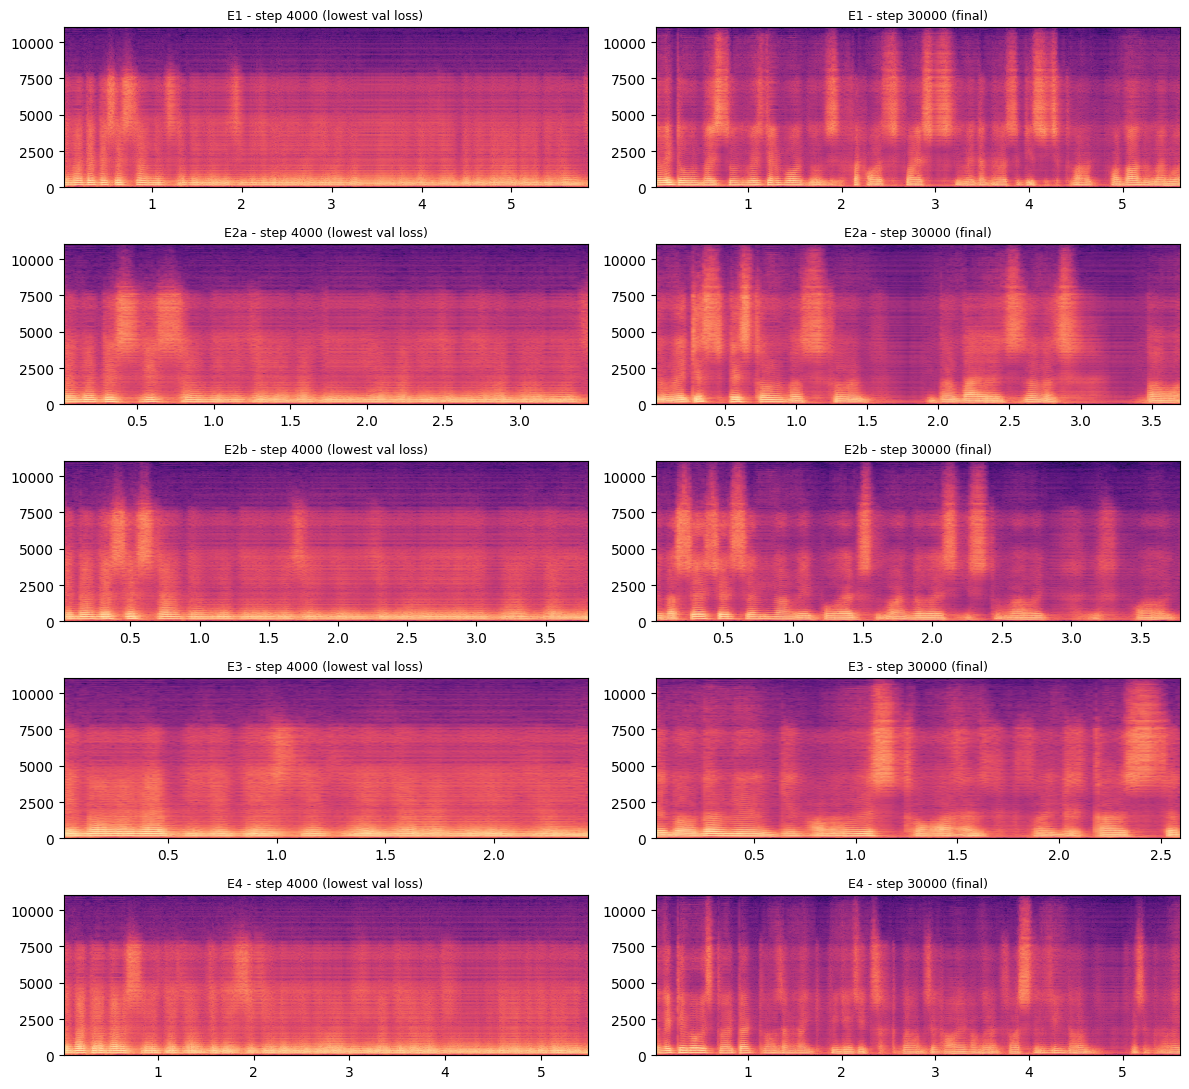

In [23]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(len(txt), 2, figsize=(12, 2.2 * len(txt)))
for i, sid in enumerate(txt):
    for j, (name, title) in enumerate((('best_step4000', 'step 4000 (lowest val loss)'), ('last_step30000', 'step 30000 (final)'))):
        x, sr = sf.read(C + '/' + name + '/test_generated_audios/' + sid + '.wav')
        ax[i, j].specgram(x, NFFT=1024, Fs=sr, noverlap=768, cmap='magma')
        ax[i, j].set_title(sid + ' - ' + title, fontsize=9)
plt.tight_layout(); plt.savefig(R + '/checkpoint_comparison.png', dpi=110); plt.show()

In [24]:
import pandas as pd
tr = pd.read_csv('/content/work/log/train_loss.csv'); va = pd.read_csv('/content/work/log/val_loss.csv')
print(va.columns.tolist())
print('best validation row:'); print(va.loc[va.iloc[:, 1].idxmin()])
print('final validation row:'); print(va.iloc[-1])
print('final train row:'); print(tr.iloc[-1])

['step', 'total', 'mel', 'postnet', 'pitch', 'energy', 'duration', 'seconds']
best validation row:
step        4000.00000
total          3.33814
mel            0.93380
postnet        0.93369
pitch          0.48769
energy         0.78828
duration       0.19468
seconds     1881.00000
Name: 7, dtype: float64
final validation row:
step        30000.00000
total           3.59954
mel             1.00840
postnet         1.00841
pitch           0.55456
energy          0.85328
duration        0.17490
seconds      1891.00000
Name: 59, dtype: float64
final train row:
step        30000.00000
total           1.69884
mel             0.49485
postnet         0.49414
pitch           0.22035
energy          0.34377
duration        0.14573
seconds      1881.00000
Name: 605, dtype: float64


In [8]:
code = r"""
# Diagnostic: model problem or data problem?
# gt = real mel through the vocoder; teacher = model with TRUE durations/pitch/energy;
# predicted = normal text-to-speech path. Done for validation and training utterances.
import os, sys, json, argparse
ap = argparse.ArgumentParser()
ap.add_argument('--lang_dir', required=True); ap.add_argument('--checkpoint', default='last')
ap.add_argument('--out_dir', required=True); ap.add_argument('--n', type=int, default=3)
a = ap.parse_args()
ROOT = os.path.dirname(a.lang_dir.rstrip('/'))
sys.path.insert(0, ROOT)
from common.configio import load_config, setup_paths
setup_paths()
import numpy as np, torch
from scipy.io import wavfile
from torch.utils.data import DataLoader
cfg, configs = load_config(os.path.join(a.lang_dir, 'config.yaml'))
pre, mod, tr = configs
from dataset import Dataset
from model import FastSpeech2
from utils.model import get_vocoder, vocoder_infer
from utils.tools import to_device
from common import synth
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ck = a.checkpoint
if ck in ('best', 'last'):
    ck = os.path.join(tr['path']['ckpt_path'], '%s_model_fp16.pth' % ck)
model = FastSpeech2(pre, mod).to(dev); synth.load_weights(model, ck, dev)
voc = get_vocoder(mod, dev)
sr = pre['preprocessing']['audio']['sampling_rate']; hop = pre['preprocessing']['stft']['hop_length']
os.makedirs(a.out_dir, exist_ok=True)
info = {}; bs = tr['optimizer']['batch_size']
for split in ('val', 'train'):
    ds = Dataset(split + '.txt', pre, tr, sort=False, drop_last=False)
    loader = DataLoader(ds, batch_size=bs * 4, shuffle=False, collate_fn=ds.collate_fn)
    batch = to_device(next(iter(loader))[0], dev)
    (ids, raw, spk, texts, src_lens, max_src, mels, mel_lens, max_mel, pit, ene, dur) = batch
    with torch.no_grad():
        tf = model(*batch[2:])
    for i in range(min(a.n, len(ids))):
        L = int(src_lens[i]); T = int(mel_lens[i])
        def wav(mel, frames):
            return vocoder_infer(mel.unsqueeze(0).transpose(1, 2), voc, mod, pre, lengths=[frames * hop])[0]
        with torch.no_grad():
            pr = model(spk[i:i + 1], texts[i:i + 1, :L], src_lens[i:i + 1], L)
        pm = int(pr[9][0])
        for tag, w in (('gt', wav(mels[i, :T], T)), ('teacher', wav(tf[1][i, :T], T)), ('predicted', wav(pr[1][0, :pm], pm))):
            wavfile.write(os.path.join(a.out_dir, '%s%d_%s.wav' % (split, i, tag)), sr, w)
        info['%s%d' % (split, i)] = raw[i]; print('%s%d: %s' % (split, i, raw[i]))
json.dump(info, open(os.path.join(a.out_dir, 'texts.json'), 'w'), ensure_ascii=False, indent=1)
print('written to', a.out_dir)
"""
open('/content/project/English/diag_check.py', 'w').write(code)
sh('python English/diag_check.py --lang_dir /content/project/English --checkpoint last --out_dir /content/project/Results/English/extra/diagnostics')

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
val0: he grew up under the influence of the hindi film industry.
val1: also music has a very
val2: and after worshipping, i sun-dry these flowers
train0: you can enjoy the himalayan forests, gushing river waters, a serene himalayan lake, clear view of snow-clad mountain ranges, widely spread cool bagyals
train1: from all over the state, as well as from the neighboring states.
train2: or we could have homegrown fresh veggies for our cooking and
written to /content/project/Results/English/extra/diagnostics


'/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.\n  WeightNorm.apply(module, name, dim)\nRemoving weight norm...\nval0: he grew up under the influence of the hindi film industry.\nval1: also music has a very\nval2: and after worshipping, i sun-dry these flowers\ntrain0: you can enjoy the himalayan forests, gushing river waters, a serene himalayan lake, clear view of snow-clad mountain ranges, widely spread cool bagyals\ntrain1: from all over the state, as well as from the neighboring states.\ntrain2: or we could have homegrown fresh veggies for our cooking and\nwritten to /content/project/Results/English/extra/diagnostics\n'

In [9]:
for d in ('ckpt', 'log'):
    target = '/content/drive/MyDrive/fs2_english/' + d
    link = '/content/work/' + d
    if not os.path.islink(link):
        if os.path.exists(link):
            shutil.rmtree(link)
        os.symlink(target, link)
print(os.listdir('/content/work/ckpt'))

['best_model_fp16.pth', 'last_model_fp16.pth', 'resume.pth.tar']


In [10]:
import json, re, torch, soundfile as sf
from transformers import pipeline
asr = pipeline('automatic-speech-recognition', model='openai/whisper-small', device=-1)
D = '/content/project/Results/English/extra/diagnostics'
texts = json.load(open(D + '/texts.json'))
def words(t): return re.sub(r"[^a-z0-9' ]", ' ', t.lower()).split()
def wer(r, h):
    r, h = words(r), words(h); d = list(range(len(h) + 1))
    for i in range(1, len(r) + 1):
        p, d[0] = d[0], i
        for j in range(1, len(h) + 1):
            p, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, p + (r[i - 1] != h[j - 1]))
    return min(d[len(h)] / max(len(r), 1), 1.0)
for key in texts:
    for tag in ('gt', 'teacher', 'predicted'):
        x, sr = sf.read('%s/%s_%s.wav' % (D, key, tag))
        hyp = asr({'array': x.astype('float32'), 'sampling_rate': sr},
                  generate_kwargs={'language': 'english', 'task': 'transcribe', 'max_new_tokens': 60})['text']
        print(key, tag, 'WER %.2f' % wer(texts[key], hyp), '|', hyp.strip()[:90])

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


val0 gt WER 0.00 | He grew up under the influence of the Hindi film industry.


[transformers] Both `max_new_tokens` (=60) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


val0 teacher WER 1.00 | Take left and you can space right machine computer.


[transformers] Both `max_new_tokens` (=60) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (27 outputs left out)

[transformers] Both `max_new_tokens` (=60) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


train2 teacher WER 0.73 | We could have our own work fresh.


[transformers] Both `max_new_tokens` (=60) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


train2 predicted WER 1.00 | I would have been able to do so, if it is in my head, I would have been able to do so.


In [11]:
R = '/content/project/Results/English'; C = R + '/extra/checkpoint_comparison'
for name, ck in (('best_step4000', 'best'), ('last_step30000', 'last')):
    sh('python English/inference.py --checkpoint %s --out_dir %s/%s' % (ck, C, name))
    sh('python English/inference.py --checkpoint %s --g2p_mode lexicon --out_dir %s/%s/extra_plain_dictionary' % (ck, C, name))
    sh('python English/inference.py --checkpoint %s --no_normalize --out_dir %s/%s/extra_no_normalisation' % (ck, C, name))
for d in ('test_generated_audios', 'variance_adaptor_plots'):
    shutil.rmtree(R + '/' + d, ignore_errors=True)
    shutil.copytree(C + '/last_step30000/' + d, R + '/' + d)
shutil.copy(C + '/last_step30000/variance_adaptor_values.json', R + '/variance_adaptor_values.json')
sh('python English/train.py --plots_only --plots_dir ' + R)
print(sorted(os.listdir(R)))

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/best_model_fp16.pth
Removing weight norm...
main speaker: spk013 (id 13); 103 speakers in model
E1: 87 phones, 5.86 s
E2a: 51 phones, 3.46 s
E2b: 56 phones, 3.82 s
E3: 37 phones, 2.45 s
E4: 81 phones, 5.50 s
done. audio -> /content/project/Results/English/extra/checkpoint_comparison/best_step4000/test_generated_audios | plots -> /content/project/Results/English/extra/checkpoint_comparison/best_step4000/variance_adaptor_plots
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
checkpoint: /content/work/ckpt/best_model_fp16.pth
Removing weight norm...
main 

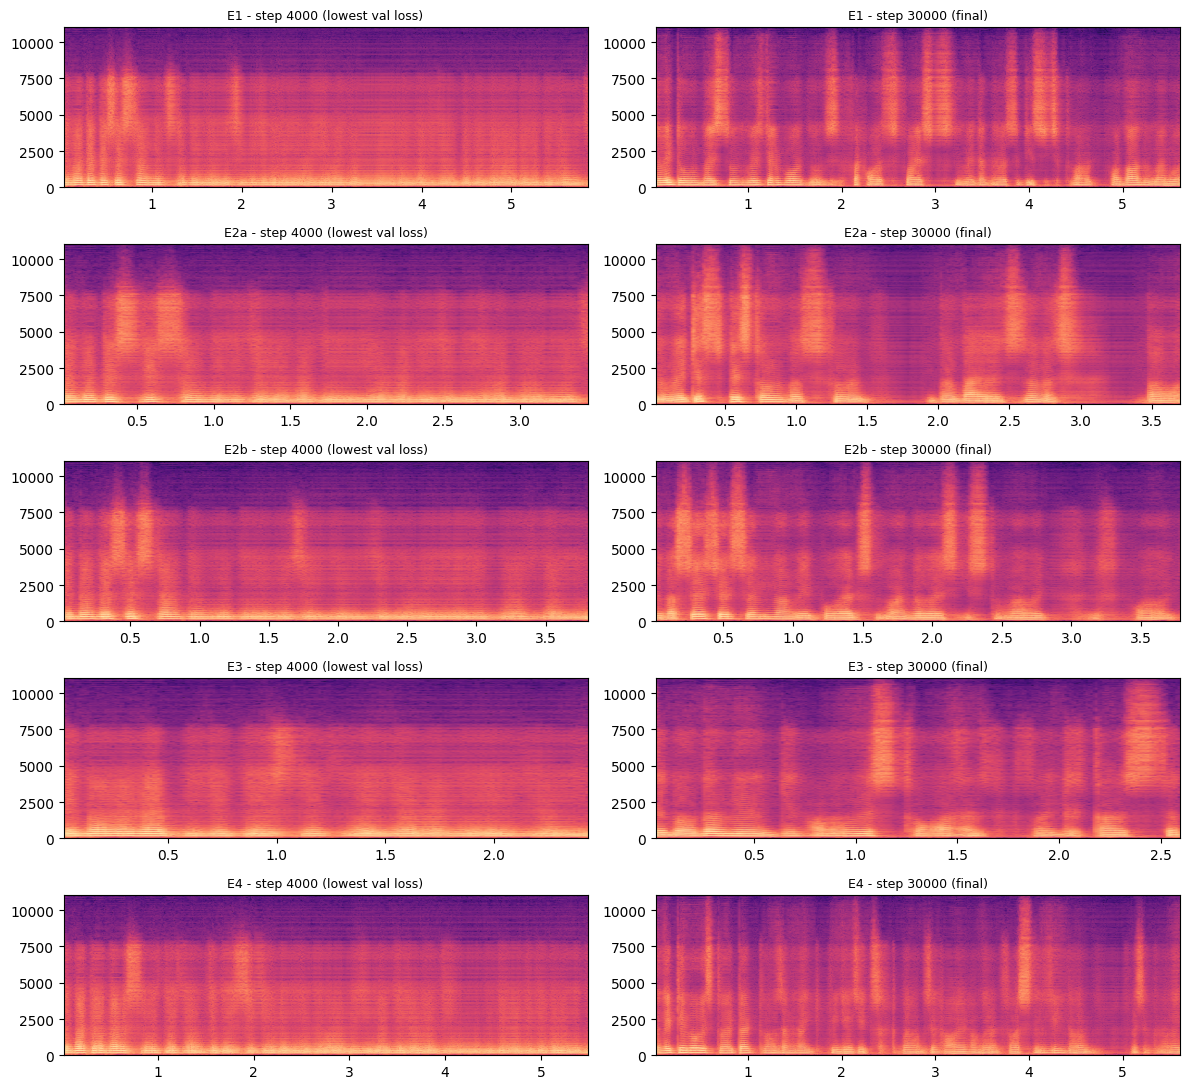

In [12]:
import json, soundfile as sf, matplotlib.pyplot as plt
txt = {s['id']: s['text'] for s in json.load(open('/content/project/English/test_sentences.json'))['sentences']}
fig, ax = plt.subplots(len(txt), 2, figsize=(12, 2.2 * len(txt)))
for i, sid in enumerate(txt):
    for j, (name, title) in enumerate((('best_step4000', 'step 4000 (lowest val loss)'), ('last_step30000', 'step 30000 (final)'))):
        x, sr = sf.read(C + '/' + name + '/test_generated_audios/' + sid + '.wav')
        ax[i, j].specgram(x, NFFT=1024, Fs=sr, noverlap=768, cmap='magma'); ax[i, j].set_title(sid + ' - ' + title, fontsize=9)
plt.tight_layout(); plt.savefig(R + '/checkpoint_comparison.png', dpi=110); plt.show()